# 第1回：演習「分布を図で確かめる」

このノートブックでは、正規分布の平均・標準偏差、共分散行列、正規性を図で確かめる。セルを上から順に実行し、図を見て問いに答える。Google Colabで実行する場合は、次のバッジからノートブックを開く。

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rsimd/data-science-j26/blob/main/exercises.ipynb)

## 準備

In [ ]:
from importlib.util import find_spec
import subprocess
import sys

if find_spec("matplotlib_fontja") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib-fontja"])


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib_fontja
from scipy import stats

rng = np.random.default_rng(2026)
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True

## Exercise 1：正規分布を生成する

平均0、標準偏差1の正規分布から5000個の値を生成し、ヒストグラムを描く。`density=True` は縦軸を確率密度にする指定である。

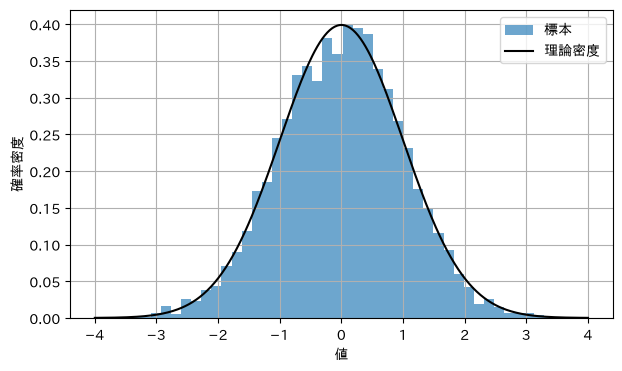

標本平均: -0.007
標本標準偏差: 1.004


In [2]:
sample = rng.normal(loc=0, scale=1, size=5000)
plt.hist(sample, bins=45, density=True, alpha=0.65, label="標本")
x = np.linspace(-4, 4, 400)
plt.plot(x, stats.norm.pdf(x), color="black", label="理論密度")
plt.xlabel("値")
plt.ylabel("確率密度")
plt.legend()
plt.show()
print(f"標本平均: {sample.mean():.3f}")
print(f"標本標準偏差: {sample.std(ddof=0):.3f}")

**確認：** 標本平均と標準偏差は理論値にどの程度近いか。完全に一致しないのはなぜか。

## Exercise 2：平均と標準偏差を変える

平均と標準偏差を変えた3つの正規分布を比べる。NumPyの `scale` には分散でなく標準偏差を指定する。

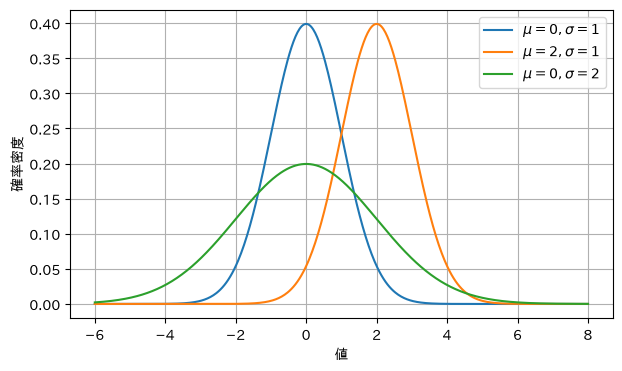

In [3]:
x = np.linspace(-6, 8, 500)
settings = [(0, 1), (2, 1), (0, 2)]
for mu, sigma in settings:
    plt.plot(x, stats.norm.pdf(x, loc=mu, scale=sigma), label=fr"$\mu={mu}, \sigma={sigma}$")
plt.xlabel("値")
plt.ylabel("確率密度")
plt.legend()
plt.show()

**確認：** 平均を変えたとき、標準偏差を変えたとき、曲線のどこが変わったかをそれぞれ説明する。

## Exercise 3：共分散行列を変える

平均を $(0,0)$ に固定し、共分散行列を変えて二次元点群を比べる。

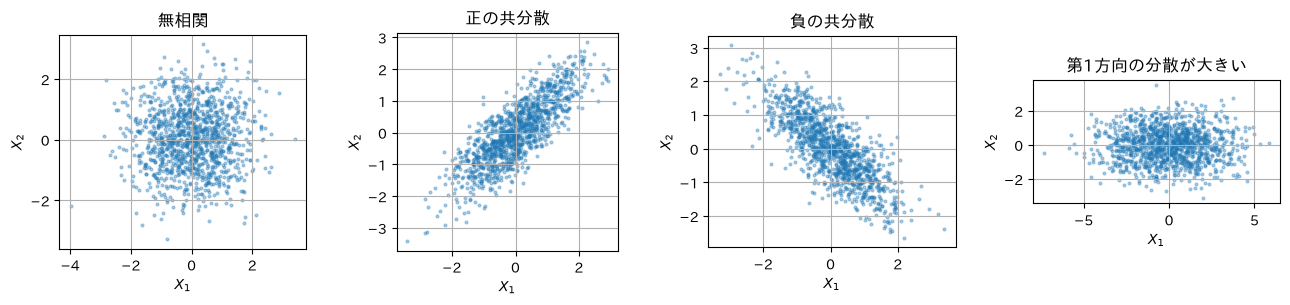

In [4]:
covariances = [
    np.array([[1, 0], [0, 1]]),
    np.array([[1, 0.8], [0.8, 1]]),
    np.array([[1, -0.8], [-0.8, 1]]),
    np.array([[4, 0], [0, 1]]),
]
titles = ["無相関", "正の共分散", "負の共分散", "第1方向の分散が大きい"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, cov, title in zip(axes, covariances, titles):
    points = rng.multivariate_normal(mean=[0, 0], cov=cov, size=1200)
    ax.scatter(points[:, 0], points[:, 1], s=4, alpha=0.35)
    ax.set_title(title)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

**確認：** 対角成分と非対角成分は、それぞれ点群のどの特徴を変えたか。共分散が負の図はどう違うか。

## Exercise 4：正規性をQ-Qプロットで見る

正規分布と一様分布からそれぞれデータを生成する。Q-Qプロットの点が基準直線に沿うか比べる。

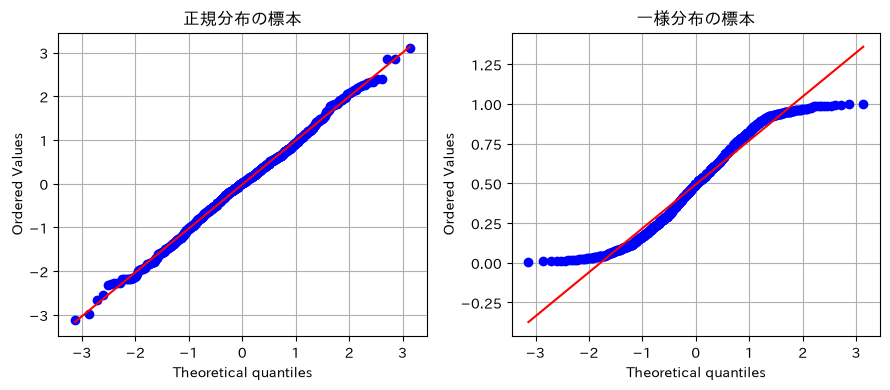

In [5]:
normal_data = rng.normal(size=800)
uniform_data = rng.uniform(size=800)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
stats.probplot(normal_data, dist="norm", plot=axes[0])
axes[0].set_title("正規分布の標本")
stats.probplot(uniform_data, dist="norm", plot=axes[1])
axes[1].set_title("一様分布の標本")
plt.tight_layout()
plt.show()

**確認：** どちらのデータが直線に沿うか。点が直線から系統的に外れるとき、データの分布について何が言えそうか。

## 提出前の振り返り

1. 正規分布の平均と分散は図のどの特徴を決めるか。
2. 共分散行列の対角成分・非対角成分はそれぞれ何を表すか。
3. ヒストグラムやQ-Qプロットだけで正規性を断定できない理由は何か。
4. 今日わかったことと、まだ説明しにくいことを1つずつ記す。